# num_runs에 따른 최종 ε 분포 축소 실험 (개편판 역산)

CAPRI 논문 **Fig. 5**(`num_runs` 증가에 따른 선택 ε의 수렴)에 대응하는 실험입니다.
개편판 역산 알고리즘을 고정된 조건에서 `outer_reps`번 독립 수행하고, 각 수행이 내보내는
**최종 ε(내부 `num_runs` 시행의 평균)** 의 분포가 `num_runs`를 키울수록 좁아지는지 확인합니다.

---

## ⚠️ GPU 결론 (먼저 읽어주세요)

**이 실험은 GPU로 단축되지 않습니다.** 병목이 연산이 아니기 때문입니다.

| 항목 | 실측값 |
|---|---|
| 병목의 정체 | 질의 1건마다 도는 `scipy.stats.t.ppf` + pandas 행 생성 (연산 자체가 아님) |
| 벡터화 후 정확도 | 200 시행 **k_stop·라운드 완전 일치** (오차 0) |
| 속도 | 36.84 ms/시행 → **0.221 ms/시행** = **167배** |
| 전체 실험(30 × 200 = 6,000 시행) | 참조 약 3.7분 → **벡터화 1.3초** |

**GPU가 도움이 안 되는 이유**
1. 필요한 float64 연산량이 3.6M 샘플(약 29MB)로 GPU를 채우기엔 너무 작아, 커널 실행·메모리 전송 오버헤드가 지배합니다.
2. Colab 무료 T4는 **FP64가 FP32의 1/32 속도**입니다(T4: FP64 0.254 TFLOPS vs FP32 8.141 TFLOPS). 이 실험은 float64가 필요하므로 GPU 커널이 오히려 CPU보다 느려질 수 있습니다.

따라서 이 노트북은 **벡터화 CPU 경로**로 구성했고, GPU 경로는 넣지 않았습니다.
**런타임 유형은 CPU로 두시면 됩니다.**

---

## 사용 순서
1. **1절** 데이터 준비 — `data/CardBase.csv`가 있으면 그대로, 없으면 합성 데이터로 자동 대체됩니다.
2. **4절** 검증·벤치마크 — 이 노트북의 엔진이 원 구현과 동일한 답을 내는지, 얼마나 빠른지 직접 확인합니다.
3. **6절** 분포 축소 실험 — `sweep_num_runs()` 실행 후 `plot_num_runs_convergence()`.
4. **8절** 해석 주의사항을 반드시 확인하세요.


In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats
import time
from pathlib import Path

plt.rcParams.update({
    "figure.dpi": 120, "savefig.dpi": 300, "font.size": 10,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.alpha": 0.22,
})

ALPHA = 0.05   # 95% 신뢰구간
MAXQ  = 500    # 질의 횟수 상한

print("numpy", np.__version__, "| pandas", pd.__version__)

numpy 2.5.2 | pandas 3.0.5


## 1. 데이터 준비

엔진이 실제로 사용하는 값은 **`delta`(민감도)** 와 **`true_mean`(모평균)** 두 개뿐입니다.
응답은 `true_mean + Laplace(0, delta/eps)` 로 생성되므로 원본 배열 `x`는 통계량 산출에만 쓰입니다.
따라서 CSV가 없어도 **합성 데이터로 실험 전체가 동작**합니다.


In [ ]:
DATASETS = {
    "CardBase": {"path": Path("data/CardBase.csv"),      "column": "Credit_Limit"},
    "Bank":     {"path": Path("data/bank_exp.parquet"),  "column": "credit_limit"},
}

def load_dataset(path, column):
    path = Path(path)
    if path.suffix.lower() == ".csv":
        df = pd.read_csv(path)
    elif path.suffix.lower() == ".parquet":
        df = pd.read_parquet(path)
    else:
        raise ValueError(f"지원하지 않는 파일 형식: {path}")
    if column not in df.columns:
        raise KeyError(f"{path}에 {column!r} 열이 없습니다.")
    x = pd.to_numeric(df[column], errors="coerce").dropna().to_numpy(float)
    if len(x) == 0:
        raise ValueError(f"{path}의 {column!r} 열에 유효한 숫자가 없습니다.")
    n = len(x)
    return {"x": x, "n": n, "true_mean": float(x.mean()),
            "min": float(x.min()), "max": float(x.max()),
            "delta": float((x.max() - x.min()) / n)}

def synthetic_dataset(n=500, true_mean=250000.0, delta=1794.0, seed=0):
    '''CSV가 없을 때 쓰는 대체 데이터. (max-min)/n = delta 가 되도록 구성한다.'''
    rng = np.random.default_rng(seed)
    x = rng.uniform(-delta * n / 2, delta * n / 2, n) + true_mean
    return {"x": x, "n": n, "true_mean": float(x.mean()),
            "min": float(x.min()), "max": float(x.max()),
            "delta": float((x.max() - x.min()) / n)}

DATA = {}
for name, cfg in DATASETS.items():
    try:
        DATA[name] = load_dataset(cfg["path"], cfg["column"])
        d = DATA[name]
        print(f"{name:9s}: 로드 완료 | n={d['n']:>7,} | delta={d['delta']:>10.2f} | true_mean={d['true_mean']:>12.2f}")
    except Exception as e:
        print(f"{name:9s}: 로드 실패 ({type(e).__name__}: {e})")

DATA.setdefault("Synthetic", synthetic_dataset())
print("\n사용 가능한 데이터셋:", list(DATA))
pd.DataFrame([{"dataset": k, **{kk: vv for kk, vv in v.items() if kk != 'x'}}
              for k, v in DATA.items()])

CardBase : 로드 완료 | n=    500 | delta=   1794.00 | true_mean=   252614.00
Bank     : 로드 완료 | n=  6,744 | delta=      4.90 | true_mean=     9074.48

사용 가능한 데이터셋: ['CardBase', 'Bank', 'Synthetic']


,dataset,n,true_mean,min,max,delta
0,CardBase,500,252614.000000,2000.000000,899000.000000,1794.000000
1,Bank,6744,9074.479537,1439.000000,34516.000000,4.904656
2,Synthetic,500,277591.697989,-198230.280974,695997.312403,1788.455187


## 2. 벡터화 엔진

원 구현의 두 가지 병목을 제거합니다.

- **`scipy.stats.t.ppf`를 루프에서 제거** — t 분위수는 `k`에만 의존하므로 `k_max`별로 **한 번에 벡터로** 계산해 재사용합니다(`t_table`).
- **pandas 행 생성을 제거** — 한 라운드의 `k_max`개 응답을 **한 번에 생성**하고, 누적평균·누적분산·상대폭·streak을 **행렬 연산으로** 계산합니다.

### streak 판정의 벡터화
연속 `streak_required`회 조건 충족을 찾는 것은 "마지막으로 조건이 깨진 위치"를 추적하면 됩니다.

```
run = idx - maximum.accumulate( where(not hit, idx, -1) )
k_stop = 첫 번째 idx where run >= streak_required  (+1)
```

이 방식은 원 구현의 실시간 streak 판정과 **수학적으로 동일**하며(4절에서 실측 검증), 라운드가 진행 중이어도
시행 단위로 병렬 처리할 수 있게 해줍니다.

### 라운드 루프의 벡터화
`eps_total`은 `initial_eps_total × step^(round-1)` 로 **모든 시행에 대해 동일한 결정값**입니다.
따라서 라운드 r에서 살아남은 시행들은 모두 같은 `k_max`를 가지므로, **시행 축으로 한꺼번에** 시뮬레이션하고
성공한 시행만 집합에서 제거하면 됩니다.


In [3]:
_T_TABLE = {}

def t_table(kmax, alpha=ALPHA):
    '''k=2..kmax 에 대한 t 분위수 표. k에만 의존하므로 한 번만 계산해 캐시한다.'''
    key = (int(kmax), float(alpha))
    if key not in _T_TABLE:
        ks = np.arange(2, int(kmax) + 1)
        _T_TABLE[key] = stats.t.ppf(1 - alpha / 2, df=ks - 1)
    return _T_TABLE[key]


def _vec_round(seeds, kmax, scale, true_mean, threshold, streak_required, alpha=ALPHA):
    '''한 라운드에 살아 있는 시행들을 동시에 시뮬레이션한다.

    seeds : (n,) 각 시행의 이 라운드 시드
    반환 : (k_stop(n,), ok(n,), relw(n,kmax), cummean(n,kmax), moe(n,kmax))
           k_stop은 1-indexed 질의 수, 실패 시행은 ok=False, k_stop=0
    '''
    n = len(seeds)
    kmax = int(kmax)

    # 1) 응답 생성: 시행마다 독립 난수 스트림. size=k 호출은 k번 스칼라 호출과 완전히 동일한 수열.
    d = np.empty((n, kmax))
    for i, s in enumerate(seeds):
        d[i] = np.random.default_rng(int(s)).laplace(0.0, scale, size=kmax)

    idx = np.arange(kmax)
    karr = (idx + 1).astype(float)

    # 2) 누적합 → 누적평균 / 누적표본분산
    S1 = np.cumsum(d, axis=1)
    S2 = np.cumsum(d * d, axis=1)
    varnum = S2 - S1 * S1 / karr                      # = sum((d-m_k)^2)
    var = np.where(idx + 1 >= 2, np.maximum(varnum, 0.0) / np.maximum(karr - 1, 1), np.nan)
    sd = np.sqrt(var)

    tvals = np.full(kmax, np.nan)
    if kmax >= 2:
        tvals[1:] = t_table(kmax, alpha)

    cummean = true_mean + S1 / karr
    moe = tvals * sd / np.sqrt(karr)
    ciw = 2 * moe
    relw = np.where(cummean != 0, ciw / np.abs(cummean), np.inf)
    relw = np.where(idx + 1 >= 2, relw, np.nan)       # k=1 은 정의되지 않음

    # 3) streak 실시간 판정의 벡터화
    hit = np.isfinite(relw) & (relw < threshold)
    last_break = np.maximum.accumulate(np.where(~hit, idx, -1), axis=1)
    run = idx - last_break
    found = run >= streak_required
    ok = found.any(axis=1)
    kstop = np.where(ok, found.argmax(axis=1) + 1, 0)
    return kstop, ok, relw, cummean, moe


def _vec_run(data, eps, threshold, streak_required, initial_eps_total, step,
             num_runs, max_rounds=20, maxq=MAXQ, seed0=2026):
    '''개편판 역산의 라운드 루프 + 시행 루프를 벡터화한 코어.

    반환: (actual_eps_total(n,), rounds_used(n,))  — 미수렴 시행은 NaN
    '''
    seeds0 = np.array([int(seed0) + r for r in range(num_runs)], dtype=np.int64)
    eps_total = float(initial_eps_total)
    res = np.full(num_runs, np.nan)
    rounds_used = np.full(num_runs, np.nan)
    active = np.arange(num_runs)

    for round_no in range(1, int(max_rounds) + 1):
        if len(active) == 0:
            break
        k_max = int(eps_total // eps)
        if k_max > maxq:
            raise ValueError(f"round={round_no}에서 k_max={k_max}가 maxq={maxq}를 초과합니다. "
                             f"initial_eps_total 또는 step을 줄이세요.")
        if k_max < 2:
            eps_total *= step
            continue

        round_seeds = seeds0[active] + round_no * 1_000_003
        kstop, ok, _, _, _ = _vec_round(round_seeds, k_max, data["delta"] / eps,
                                        data["true_mean"], threshold, streak_required)

        succ = active[ok]
        res[succ] = eps * kstop[ok]
        rounds_used[succ] = round_no
        active = active[~ok]
        eps_total *= step

    return res, rounds_used

## 3. 검증용 참조 구현

4절에서 벡터화 엔진이 원 구현과 **완전히 같은 답**을 내는지 확인하기 위한 스칼라 구현입니다.
`dp_inverse.py`의 `_statistics` / `run_inverse_live` 로직을 그대로 옮긴 것이며, **실험에는 쓰지 않습니다.**


In [4]:
def _statistics(values, true_mean, alpha=ALPHA):
    '''원 구현과 동일: 누적 통계 + 95% CI (스칼라).'''
    values = np.asarray(values, dtype=float)
    k = len(values)
    cm = float(values.mean())
    if k < 2:
        return {"k": k, "response": float(values[-1]), "cumulative_mean": cm,
                "sample_std": np.nan, "standard_error": np.nan, "moe": np.nan,
                "ci_lo": np.nan, "ci_hi": np.nan, "ci_width": np.nan,
                "relative_width": np.nan, "hit": False, "covered": None}
    sd = float(values.std(ddof=1))
    se = sd / np.sqrt(k)
    t = stats.t.ppf(1 - alpha / 2, df=k - 1)
    moe = float(t * se)
    ci_lo, ci_hi = cm - moe, cm + moe
    ciw = float(2 * moe)
    relw = float(ciw / abs(cm)) if cm != 0 else np.inf
    return {"k": k, "response": float(values[-1]), "cumulative_mean": cm,
            "sample_std": sd, "standard_error": se, "moe": moe,
            "ci_lo": ci_lo, "ci_hi": ci_hi, "ci_width": ciw,
            "relative_width": relw, "hit": False,
            "covered": bool(ci_lo <= true_mean <= ci_hi)}


def _ref_trial(data, eps, threshold, streak_required, initial_eps_total, step,
               max_rounds, maxq, seed):
    '''원 구현 방식의 단일 시행(라운드 루프 + 스칼라 streak 판정).'''
    eps_total = float(initial_eps_total)
    for round_no in range(1, int(max_rounds) + 1):
        k_max = int(eps_total // eps)
        if k_max > maxq:
            raise ValueError("maxq")
        if k_max < 2:
            eps_total *= step
            continue
        rng = np.random.default_rng(int(seed + round_no * 1_000_003))
        scale = data["delta"] / eps
        responses, streak_count, stopped_k = [], 0, None
        for local_k in range(1, k_max + 1):
            responses.append(float(data["true_mean"] + rng.laplace(0.0, scale)))
            row = _statistics(responses, data["true_mean"], ALPHA)
            hit = bool(np.isfinite(row["relative_width"]) and row["relative_width"] < threshold)
            streak_count = streak_count + 1 if hit else 0
            if streak_count >= streak_required:
                stopped_k = local_k
                break
        if stopped_k is not None:
            return float(eps * stopped_k), round_no, stopped_k
        eps_total *= step
    return np.nan, int(max_rounds), np.nan


def _trial_trajectory(data, eps, threshold, streak_required, initial_eps_total, step,
                      max_rounds, maxq, seed):
    '''단일 시행의 전 질의 시점 궤적(성공 라운드 기준). 개별 시행 점검용.'''
    eps_total = float(initial_eps_total)
    for round_no in range(1, int(max_rounds) + 1):
        k_max = int(eps_total // eps)
        if k_max < 2:
            eps_total *= step
            continue
        rng = np.random.default_rng(int(seed + round_no * 1_000_003))
        scale = data["delta"] / eps
        responses, rows, streak_count, stopped_k = [], [], 0, None
        for local_k in range(1, k_max + 1):
            responses.append(float(data["true_mean"] + rng.laplace(0.0, scale)))
            row = _statistics(responses, data["true_mean"], ALPHA)
            hit = bool(np.isfinite(row["relative_width"]) and row["relative_width"] < threshold)
            streak_count = streak_count + 1 if hit else 0
            row.update({"round": round_no, "k_max": k_max, "actual_eps_total": eps * local_k,
                        "hit": hit, "streak_count": streak_count})
            rows.append(row)
            if streak_count >= streak_required:
                stopped_k = local_k
                break
        if stopped_k is not None:
            return pd.DataFrame(rows)
        eps_total *= step
    return pd.DataFrame(rows) if rows else pd.DataFrame()

## 4. 검증 + 벤치마크

두 가지를 확인합니다.

1. **수열 동일성** — `rng.laplace(0, scale, size=k)` 가 스칼라 호출 k번과 같은 수열을 내는지
2. **결과 동일성** — 같은 시드 집합에서 벡터화 엔진의 `k_stop`·라운드가 참조 구현과 일치하는지

여기서 불일치가 0이 아니면 아래 실험 결과를 신뢰할 수 없습니다.


In [5]:
# --- 검증 설정 ---
V_DATA = DATA.get("CardBase", DATA["Synthetic"])
V_CFG  = dict(eps=0.1, threshold=0.05, streak_required=3,
              initial_eps_total=3.0, step=1.03, max_rounds=50, maxq=MAXQ, seed0=2025)
V_N    = 200

# --- 검증 1: 난수 수열 동일성 ---
_r = np.random.default_rng(7)
_a = np.array([float(_r.laplace(0.0, 5.0)) for _ in range(10)])
_b = np.random.default_rng(7).laplace(0.0, 5.0, size=10)
print("검증1  size=k 호출 == 스칼라 k회 호출 :", bool(np.array_equal(_a, _b)))

# --- 검증 2: k_stop / 라운드 일치 ---
t0 = time.time()
_ref = [_ref_trial(V_DATA, V_CFG["eps"], V_CFG["threshold"], V_CFG["streak_required"],
                   V_CFG["initial_eps_total"], V_CFG["step"], V_CFG["max_rounds"],
                   V_CFG["maxq"], V_CFG["seed0"] + r) for r in range(V_N)]
t_ref = time.time() - t0

t0 = time.time()
_vec_eps, _vec_rn = _vec_run(V_DATA, V_CFG["eps"], V_CFG["threshold"], V_CFG["streak_required"],
                             V_CFG["initial_eps_total"], V_CFG["step"], V_N,
                             V_CFG["max_rounds"], V_CFG["maxq"], V_CFG["seed0"])
t_vec = time.time() - t0

ref_eps = np.array([x[0] for x in _ref]); ref_rn = np.array([x[1] for x in _ref])
same_eps = np.allclose(ref_eps, _vec_eps, equal_nan=True)
same_rn  = bool((ref_rn == _vec_rn).all())

print(f"검증2  eps 일치: {same_eps} | 라운드 일치: {same_rn} "
      f"| 불일치 {int((~np.isclose(ref_eps, _vec_eps, equal_nan=True)).sum())}건")
print(f"       수렴: 참조 {int(np.isfinite(ref_eps).sum())}/{V_N}  벡터화 {int(np.isfinite(_vec_eps).sum())}/{V_N}")

print(f"\n벤치마크 ({V_N} 시행)")
print(f"  참조 구현   : {t_ref:7.2f} s  ({t_ref/V_N*1000:7.2f} ms/시행)")
print(f"  벡터화 엔진 : {t_vec:7.3f} s  ({t_vec/V_N*1000:7.3f} ms/시행)")
print(f"  속도 향상   : {t_ref/max(t_vec,1e-9):.0f}x")

_full = 30 * 200
print(f"\n전체 실험 예상 (outer_reps=30 x num_runs=200 = {_full:,} 시행)")
print(f"  참조 구현   : {t_ref/V_N*_full/60:.1f} 분")
print(f"  벡터화 엔진 : {t_ref/V_N*_full/max(t_ref/max(t_vec,1e-9),1e-9):.1f} 초")

assert same_eps and same_rn, "검증 실패: 아래 실험 결과를 신뢰할 수 없습니다."
print("\n✅ 검증 통과 — 벡터화 엔진은 참조 구현과 동일한 결과를 냅니다.")

검증1  size=k 호출 == 스칼라 k회 호출 : True
검증2  eps 일치: True | 라운드 일치: True | 불일치 0건
       수렴: 참조 200/200  벡터화 200/200

벤치마크 (200 시행)
  참조 구현   :    3.65 s  (  18.24 ms/시행)
  벡터화 엔진 :   0.028 s  (  0.142 ms/시행)
  속도 향상   : 129x

전체 실험 예상 (outer_reps=30 x num_runs=200 = 6,000 시행)
  참조 구현   : 1.8 분
  벡터화 엔진 : 0.9 초

✅ 검증 통과 — 벡터화 엔진은 참조 구현과 동일한 결과를 냅니다.


## 5. 개편판 역산 (`num_runs` 포함)

3층 구조를 그대로 유지합니다.

| 층 | 역할 |
|---|---|
| 층1 (최내부) | 질의 1건 추가 → 상대폭 < `threshold`면 streak +1, 아니면 0으로 초기화. `streak_required` 도달 시 즉시 정지 |
| 층2 (라운드) | `k_max = floor(eps_total / eps)`회 관찰. 조기 성공 시 `actual_eps_total = eps × k_stop`, 실패 시 `eps_total ×= step` 후 다음 라운드 |
| 층3 (`num_runs`) | 시행별 독립 시드로 층1+층2를 `num_runs`번 수행 → **실제 소모 ε의 평균**을 최종 ε으로 선택 |

**주의**: 반환 시그니처가 이전 `run_inverse_live`와 다릅니다. 이 함수는 `(trial_finals, final_eps)`만 돌려줍니다.
전체 궤적을 시행 수만큼 쌓으면 메모리가 폭발하므로, 필요한 시행만 `_trial_trajectory()`로 재생성합니다.


In [6]:
def run_inverse_live_vec(data, eps, threshold, streak_required, initial_eps_total, step,
                         num_runs=10, max_rounds=20, maxq=MAXQ, seed0=2026, alpha=ALPHA,
                         eps_decimals=2, verbose=False):
    '''개편판 역산 알고리즘의 단일 수행(벡터화).

    시뮬레이션 1회 = num_runs번의 독립 시행을 평균해 최종 ε 하나를 낸다.
    반환: (trial_finals DataFrame, final_eps)
    '''
    if num_runs < 1:
        raise ValueError("num_runs는 1 이상이어야 합니다.")
    if step <= 1:
        raise ValueError("step은 1보다 커야 합니다.")

    res, rounds_used = _vec_run(data, eps, threshold, streak_required, initial_eps_total,
                                step, num_runs, max_rounds, maxq, seed0)

    tf = pd.DataFrame({
        "method": "INVERSE",
        "rep": np.arange(1, num_runs + 1),
        "seed": np.array([int(seed0) + r for r in range(num_runs)], dtype=np.int64),
        "rounds_used": rounds_used,
        "actual_eps_total": res,
        "eps": float(eps), "threshold": float(threshold),
        "streak_required": int(streak_required),
        "step": float(step), "initial_eps_total": float(initial_eps_total),
        "delta": float(data["delta"]), "true_mean": float(data["true_mean"]),
    })
    tf["k_stop"] = pd.array(np.round(res / eps), dtype="Int64")

    n_conv = int(np.isfinite(res).sum())
    final_eps = round(float(np.nanmean(res)), eps_decimals) if n_conv else np.nan

    if verbose:
        print(f"num_runs={num_runs} | 수렴={n_conv}/{num_runs} | "
              f"평균 ε={final_eps} (소수 {eps_decimals}자리)")

    return tf, final_eps


def representative_trial(trial_finals):
    '''actual_eps_total을 정렬해 가운데 순위의 시행을 고른다(짝수면 작은 쪽).'''
    v = trial_finals["actual_eps_total"].astype(float)
    finite = v[np.isfinite(v)]
    if len(finite) == 0:
        return None
    pos = (len(finite) - 1) // 2
    target = float(finite.sort_values().iloc[pos])
    return trial_finals[np.isclose(v, target)].iloc[0]

## 6. 분포 축소 실험

**2중 반복**을 구분해야 합니다.

| 층 | 의미 | 산출 |
|---|---|---|
| 내부 `num_runs` | 한 실험 안에서 시행을 평균 | `final_eps` **1개** |
| 외부 `outer_reps` | 그 실험 자체를 반복 | `final_eps`의 **분포** ← 지금 필요한 것 |

즉 여기서 보는 것은 **"평균 추정량의 분포"** 이고, `num_runs`를 키우면 이 분포가 **좁아지는지**를 확인합니다.

**시드 규칙**: 실험 r의 `seed0 = base_seed0 + (r-1) × outer_stride` (stride = 1,000,000,007).
서로 다른 실험이 시드를 공유하지 않도록 크게 잡았습니다.


In [14]:
def run_inverse_live_repeated(data, eps, threshold, streak_required,
                              initial_eps_total, step, num_runs,
                              outer_reps=30, max_rounds=20, maxq=MAXQ,
                              base_seed0=2025, alpha=ALPHA, eps_decimals=2,
                              outer_stride=1_000_000_007, verbose=False):
    '''고정된 num_runs에서 개편판 역산을 outer_reps번 독립 수행한다.

    반환된 final_eps의 분포가 곧 '평균 추정량의 분포'이다.
    '''
    rows = []
    for r in range(1, outer_reps + 1):
        seed0 = int(base_seed0 + (r - 1) * outer_stride)
        tf, final_eps = run_inverse_live_vec(
            data, eps=eps, threshold=threshold, streak_required=streak_required,
            initial_eps_total=initial_eps_total, step=step, num_runs=num_runs,
            max_rounds=max_rounds, maxq=maxq, seed0=seed0,
            alpha=alpha, eps_decimals=eps_decimals, verbose=False)
        v = tf["actual_eps_total"].astype(float).to_numpy()
        n_conv = int(np.isfinite(v).sum())
        rows.append({
            "num_runs": int(num_runs), "outer_rep": r, "seed0": seed0,
            "final_eps": float(final_eps) if np.isfinite(final_eps) else np.nan,
            "trial_mean": float(np.nanmean(v)) if n_conv else np.nan,
            "trial_median": float(np.nanmedian(v)) if n_conv else np.nan,
            "trial_std": float(np.nanstd(v, ddof=1)) if n_conv > 1 else np.nan,
            "trial_min": float(np.nanmin(v)) if n_conv else np.nan,
            "trial_max": float(np.nanmax(v)) if n_conv else np.nan,
            "n_converged": n_conv, "conv_rate": n_conv / num_runs,
        })
        if verbose:
            print(f"[outer {r:>3}/{outer_reps}] num_runs={num_runs:>4} | "
                  f"final_eps={final_eps} | 수렴={n_conv}/{num_runs}")
    return pd.DataFrame(rows)


def sweep_num_runs(data, eps, threshold, streak_required, initial_eps_total, step,
                   num_runs_list=(1, 5, 10, 20, 50, 100, 200),
                   outer_reps=30, max_rounds=20, maxq=MAXQ,
                   base_seed0=2025, alpha=ALPHA, eps_decimals=2, verbose=True):
    '''num_runs 값을 바꿔가며 run_inverse_live_repeated를 수행한다.'''
    frames = []
    for n in num_runs_list:
        t0 = time.time()
        df = run_inverse_live_repeated(
            data, eps=eps, threshold=threshold, streak_required=streak_required,
            initial_eps_total=initial_eps_total, step=step, num_runs=n,
            outer_reps=outer_reps, max_rounds=max_rounds, maxq=maxq,
            base_seed0=base_seed0, alpha=alpha, eps_decimals=eps_decimals)
        frames.append(df)
        if verbose:
            print(f"num_runs={n:>4} | final_eps mean={df['final_eps'].mean():.3f} "
                  f"std={df['final_eps'].std():.3f} | 수렴률={df['conv_rate'].mean():.3f} "
                  f"| {time.time()-t0:.2f}s")
    return pd.concat(frames, ignore_index=True)


def summarize_num_runs_sweep(sweep):
    '''num_runs별 final_eps 분포 요약 + 최빈 ε 점유율(CAPRI Fig.5 대응).'''
    rows = []
    for n, g in sweep.groupby("num_runs"):
        v = g["final_eps"].dropna().astype(float)
        if v.empty:
            rows.append({"num_runs": int(n), "n_valid": 0})
            continue
        vc = v.value_counts()
        rows.append({
            "num_runs": int(n), "n_outer": len(g), "n_valid": len(v),
            "mean": v.mean(), "median": v.median(), "std": v.std(ddof=1),
            "p05": v.quantile(.05), "p95": v.quantile(.95),
            "iqr": v.quantile(.75) - v.quantile(.25),
            "min": v.min(), "max": v.max(),
            "mode_eps": float(vc.index[0]), "mode_share": float(vc.iloc[0] / len(v)),
            "conv_rate_mean": g["conv_rate"].mean(),
        })
    return pd.DataFrame(rows).sort_values("num_runs").reset_index(drop=True)

In [15]:
# ============================================================================
# 분포 축소 실험 — 시각화 함수 모음
#   (A) plot_absolute_and_relative : ax1(막대) + ax2(상대 산포)  ← 나란히 배치
#   (B) plot_trial_distribution    : 산점도 (처음부터 채택)
#   (C) plot_ridge                 : Ridgeline
#   (D) plot_density_heatmap       : Density heatmap (Blues)
# ============================================================================
BLUE, RED, INK, GRAY = "#2166AC", "#D55E4A", "#2B2B2B", "#8A8A8A"


def _mood(ax):
    """모든 패널의 공통 무드 — 동일 그리드·스파인·틱."""
    ax.grid(alpha=.22, lw=.7)
    ax.set_axisbelow(True)
    for sp in ("top", "right"):
        ax.spines[sp].set_visible(False)
    ax.tick_params(labelsize=9)


def summarize_num_runs_variance(sweep):
    """num_runs별 요약 + √n 법칙 검증용 열/속성.

    추가 열 : cv(std/mean), rel_iqr(IQR/median), std_x_sqrtn(std×√n)
    추가 속성: loglog_slope(log-log 기울기, 이론 -0.5), sigma_hat(시행 1회 std 추정치)
    """
    s = summarize_num_runs_sweep(sweep).copy()
    s["cv"] = s["std"] / s["mean"]
    s["rel_iqr"] = s["iqr"] / s["median"]
    s["std_x_sqrtn"] = s["std"] * np.sqrt(s["num_runs"])

    n = s["num_runs"].to_numpy(float)
    sd = s["std"].to_numpy(float)
    ok = np.isfinite(sd) & (sd > 0)
    if ok.sum() >= 2:
        slope, intercept = np.polyfit(np.log(n[ok]), np.log(sd[ok]), 1)
        s.attrs["loglog_slope"] = float(slope)
        s.attrs["sigma_hat"] = float(s["std_x_sqrtn"].mean())
    return s

In [17]:
def plot_trial_distribution(sweep, show_std_axis=False, save=None):
    """num_runs별 final_eps 분포 — 산점도 + IQR 띠 + 평균(◆)·중앙값(○).

    show_std_axis=True 로 두면 우측 축에 std를 겹쳐 그린다.
    """
    order = sorted(sweep["num_runs"].unique())

    fig, ax = plt.subplots(figsize=(8.2, 5.0), constrained_layout=True)
    for i, v in enumerate(order):
        vals = sweep.loc[sweep["num_runs"] == v, "final_eps"].dropna().astype(float).to_numpy()
        if not len(vals):
            continue
        jit = np.linspace(-.16, .16, len(vals)) if len(vals) > 1 else np.array([0.])
        q1, med, q3 = np.quantile(vals, [.25, .5, .75])

        ax.plot([i, i], [q1, q3], color=BLUE, lw=9, alpha=.28,
                solid_capstyle="round", zorder=2)
        ax.scatter(np.full(len(vals), i) + jit, vals, s=26, color=BLUE,
                   edgecolor="white", lw=.4, zorder=3,
                   label="repeats" if i == 0 else None)
        ax.scatter([i], [med], facecolor="white", edgecolor="black", s=60,
                   zorder=4, label="median" if i == 0 else None)
        ax.scatter([i], [vals.mean()], marker="D", facecolor="black",
                   edgecolor="white", s=45, zorder=5,
                   label="mean" if i == 0 else None)

    ax.set_xticks(range(len(order)))
    ax.set_xticklabels([str(int(v)) for v in order])
    ax.set_xlabel("num_runs")
    ax.set_ylabel("Final epsilon (mean over num_runs trials)")
    ax.set_title("Distribution of the selected final epsilon")
    ax.legend(frameon=False, fontsize=9, loc="upper right")
    _mood(ax)

    if show_std_axis:                       # 우측 축에 std 겹치기
        axr = ax.twinx()
        axr.plot(range(len(order)),
                 [sweep.loc[sweep["num_runs"] == v, "final_eps"].std(ddof=1) for v in order],
                 "o--", color=GRAY, lw=1.6, ms=5, zorder=1)
        axr.set_ylabel("std of final epsilon", color=GRAY)
        axr.tick_params(axis="y", colors=GRAY, labelsize=9)
        axr.spines["top"].set_visible(False)

    if save:
        fig.savefig(save, bbox_inches="tight")
    plt.show()
    return fig

In [18]:
def plot_ridge(sweep, save=None):
    """num_runs별 밀도를 세로로 쌓은 릿지. 전역 중앙값을 점선으로 표시."""
    order = sorted(sweep["num_runs"].unique())
    groups = [sweep.loc[sweep["num_runs"] == v, "final_eps"].dropna().astype(float).to_numpy()
              for v in order]
    labels = [int(v) for v in order]

    cmap = plt.get_cmap("cividis")
    cols = [cmap(i / max(len(order) - 1, 1)) for i in range(len(order))]

    fig, ax = plt.subplots(figsize=(9.2, 5.4), constrained_layout=True)
    lo = min(v.min() for v in groups)
    hi = max(v.max() for v in groups)
    pad = (hi - lo) * .12
    grid = np.linspace(lo - pad, hi + pad, 300)

    for i, (v, c) in enumerate(zip(groups, cols)):
        dens = stats.gaussian_kde(v)(grid) if len(v) > 1 else np.zeros_like(grid)
        dens = dens / max(dens.max(), 1e-12) * 1.55          # 최고점 높이 고정
        ax.fill_between(grid, i, i + dens, color=c, alpha=.72, lw=0, zorder=3 + i)
        ax.plot(grid, i + dens, color=INK, lw=.9, alpha=.85, zorder=3 + i)
        med = np.median(v)
        ax.plot([med, med], [i, i + 1.62], color=INK, lw=1.1,
                ls=(0, (2, 1.6)), zorder=4 + i)
        ax.text(hi + pad * .55, i + .35, f"num_runs={labels[i]}\nmed={med:.2f}",
                fontsize=8, va="bottom", ha="left")

    allmed = float(np.median(np.concatenate(groups)))
    ax.axvline(allmed, color=INK, ls=":", lw=1.2, alpha=.75, zorder=2)

    ax.set_yticks(range(len(labels)))
    ax.set_yticklabels([f"num_runs={v}" for v in labels])
    ax.set_xlim(lo - pad, hi + pad * 1.9)
    ax.set_xlabel("Final epsilon")
    ax.set_title("Ridgeline — narrowing of the final-epsilon distribution")
    _mood(ax)

    if save:
        fig.savefig(save, bbox_inches="tight")
    plt.show()
    return fig

In [19]:
def plot_density_heatmap(sweep, cmap="Blues", save=None):
    """x=Final epsilon, y=num_runs, 색=밀도. cmap 기본값 Blues(확정)."""
    order = sorted(sweep["num_runs"].unique())
    labels = [int(v) for v in order]
    groups = [sweep.loc[sweep["num_runs"] == v, "final_eps"].dropna().astype(float).to_numpy()
              for v in order]

    lo = min(v.min() for v in groups)
    hi = max(v.max() for v in groups)
    bins = np.linspace(lo, hi, 40)
    M = np.zeros((len(groups), len(bins) - 1))
    for i, v in enumerate(groups):
        h, _ = np.histogram(v, bins=bins)
        M[i] = h / max(h.sum(), 1)          # 행마다 합=1 (밀도 정규화)

    fig, ax = plt.subplots(figsize=(8.5, 4.6), constrained_layout=True)
    im = ax.imshow(M, aspect="auto", origin="lower", cmap=cmap,
                   extent=[bins[0], bins[-1], -.5, len(groups) - .5])
    ax.set_yticks(range(len(labels)))
    ax.set_yticklabels([f"num_runs={v}" for v in labels])
    ax.set_xlabel("Final epsilon")
    ax.set_title("Density heatmap")
    plt.colorbar(im, ax=ax, shrink=.9, label="density")
    ax.grid(False)

    if save:
        fig.savefig(save, bbox_inches="tight")
    plt.show()
    return fig

In [54]:
def plot_absolute_and_relative(sweep, summary=None, save=None):
    """(a) 절대 std 막대 + 이론값 마커 / (b) 상대 산포 선. 좌우 나란히.

    라벨 겹침 방지
      - 막대 폭을 좁게(0.46) 잡고
      - 관측값은 '막대 위 중앙', 이론값은 '마커 오른쪽 바깥(x+0.26)'
      - 두 라벨 모두 흰 배경 박스를 깔아 어떤 상황에서도 읽히게 함
    → 값이 거의 같을 때(예: 0.271 vs 0.284)도 겹치지 않는다.
    """
    if summary is None:
        summary = summarize_num_runs_variance(sweep)
    n = summary["num_runs"].to_numpy(float)
    sd = summary["std"].to_numpy(float)
    sig = summary.attrs.get("sigma_hat", np.nan)
    theory = sig / np.sqrt(n)
    x = np.arange(len(n))

    fig, (ax, bx) = plt.subplots(1, 2, figsize=(12.6, 4.9), constrained_layout=True)

    # ---------------- (a) 절대 산포 ----------------
    ax.bar(x, sd, width=.46, color=BLUE, alpha=.80, edgecolor="white",
           lw=1.0, zorder=3, label="observed std")
    ax.plot(x, theory, "-", color=RED, lw=1.2, alpha=.45, zorder=4)
    ax.scatter(x, theory, s=95, facecolor="white", edgecolor=RED, lw=2.0,
               zorder=5, label=r"theory  $\hat\sigma/\sqrt{n}$")

    BOX = dict(boxstyle="round,pad=0.18", fc="white", ec="none", alpha=.88)
    # for xi, y in zip(x, sd):                       # 관측값: 막대 위 중앙
    #     ax.text(xi, y - 0.020, f"{y:.3f}", ha="center", va="bottom",
    #             fontsize=8.0, color=INK, zorder=6) #bbox=BOX, zorder=6)
    for xi, y in zip(x, theory):                   # 이론값: 마커 오른쪽 바깥
        ax.text(xi + 0.26, y, f"{y:.3f}", ha="left", va="center",
                fontsize=8.0, color=RED, bbox=BOX, zorder=6)

    ax.set_xticks(x)
    ax.set_xticklabels([str(int(v)) for v in n])
    ax.set_xlim(-.6, len(n) - .25)                 # 오른쪽 라벨 공간 확보
    ax.set_xlabel("num_runs")
    ax.set_ylabel("std of final epsilon")
    ax.set_title("(a) Absolute spread  —  observed vs theory")
    ax.legend(frameon=False, fontsize=9, loc="upper right")
    # ax.text(.02, .965, rf"$\hat\sigma$ = {sig:.3f}", transform=ax.transAxes,
    #         va="top", ha="left", fontsize=8.5, color=GRAY)
    _mood(ax)

    # ---------------- (b) 상대 산포 ----------------
    bx.semilogx(n, summary["cv"], "o-", color=BLUE, lw=2.0, ms=7,
                mec="white", mew=1.0, label="std / mean")
    bx.semilogx(n, summary["rel_iqr"], "s--", color=RED, lw=2.0, ms=7,
                mec="white", mew=1.0, label="IQR / median")
    for xi, y in zip(n, summary["cv"]):
        bx.text(xi, y - 0.020, f"{y:.3f}", fontsize=7.5, ha="center", va="bottom",
                color=INK, bbox=BOX)
    bx.set_xticks(n)
    bx.set_xticklabels([str(int(v)) for v in n])
    bx.minorticks_off()
    bx.set_xlabel("num_runs (log)")
    bx.set_ylabel("Relative dispersion")
    bx.set_title("(b) Relative spread  (center removed)")
    bx.legend(frameon=False, fontsize=9)
    _mood(bx)

    if save:
        fig.savefig(save, bbox_inches="tight")
    plt.show()
    return fig

## 7. 실행

먼저 **파일럿**으로 실제 소요 시간을 확인한 뒤 본 실험으로 넘어가세요.
(벡터화 덕분에 파일럿도 즉시 끝납니다. 이 단계는 파라미터가 정상 동작하는지 보는 용도입니다.)


In [8]:
D = DATA.get("CardBase", DATA["Synthetic"])
print("실험 대상:", "CardBase" if "CardBase" in DATA else "Synthetic",
      f"| delta={D['delta']:.2f} | true_mean={D['true_mean']:.2f}\n")

# ---- (1) 파일럿: 파라미터 점검 ----
pilot = run_inverse_live_repeated(
    D, eps=0.1, threshold=0.05, streak_required=3,
    initial_eps_total=3, step=1.03,
    num_runs=20, outer_reps=5, max_rounds=50, maxq=MAXQ,
    base_seed0=2025, verbose=True)
print()
display(pilot[["num_runs", "outer_rep", "final_eps", "n_converged", "conv_rate"]])

실험 대상: CardBase | delta=1794.00 | true_mean=252614.00

[outer   1/5] num_runs=  20 | final_eps=3.19 | 수렴=20/20
[outer   2/5] num_runs=  20 | final_eps=3.54 | 수렴=20/20
[outer   3/5] num_runs=  20 | final_eps=3.31 | 수렴=20/20
[outer   4/5] num_runs=  20 | final_eps=2.95 | 수렴=20/20
[outer   5/5] num_runs=  20 | final_eps=2.48 | 수렴=20/20



,num_runs,outer_rep,final_eps,n_converged,conv_rate
0,20,1,3.19,20,1.0
1,20,2,3.54,20,1.0
2,20,3,3.31,20,1.0
3,20,4,2.95,20,1.0
4,20,5,2.48,20,1.0


In [47]:
# ---- (2) 본 실험: num_runs 스윕 ----
sweep = sweep_num_runs(
    D, eps=0.1, threshold=0.05, streak_required=3,
    initial_eps_total=3, step=1.03,
    # num_runs_list=(1, 5, 10, 20, 50, 100, 200),
    num_runs_list=(1, 10, 50, 100, 200, 500),
    outer_reps=30, max_rounds=50, maxq=MAXQ,
    base_seed0=2025, verbose=True)

num_runs=   1 | final_eps mean=3.290 std=1.164 | 수렴률=1.000 | 0.32s
num_runs=  10 | final_eps mean=3.127 std=0.466 | 수렴률=1.000 | 0.17s
num_runs=  50 | final_eps mean=2.977 std=0.157 | 수렴률=1.000 | 0.54s
num_runs= 100 | final_eps mean=2.961 std=0.124 | 수렴률=1.000 | 0.67s
num_runs= 200 | final_eps mean=2.947 std=0.078 | 수렴률=1.000 | 1.18s
num_runs= 500 | final_eps mean=2.940 std=0.061 | 수렴률=1.000 | 3.76s


In [48]:
# ===== 본 실험 직후에 그대로 실행 =====
summary = summarize_num_runs_variance(sweep)

print(summary.round(4).to_string(index=False))
print(f"\nlog-log 기울기 = {summary.attrs['loglog_slope']:.4f}  (이론 -0.5)")
print(f"σ̂ = {summary.attrs['sigma_hat']:.3f}   → num_runs=1이면 std ≈ {summary.attrs['sigma_hat']:.3f}")

 num_runs  n_outer  n_valid   mean  median    std    p05    p95    iqr  min  max  mode_eps  mode_share  conv_rate_mean     cv  rel_iqr  std_x_sqrtn
        1       30       30 3.2900   3.200 1.1639 1.5800 5.0550 1.4500 0.90 5.90      3.50      0.0667             1.0 0.3538   0.4531       1.1639
       10       30       30 3.1270   2.950 0.4665 2.6405 4.0165 0.4825 2.27 4.11      2.74      0.1000             1.0 0.1492   0.1636       1.4751
       50       30       30 2.9767   2.995 0.1568 2.7690 3.2255 0.2525 2.70 3.28      3.00      0.1333             1.0 0.0527   0.0843       1.1086
      100       30       30 2.9613   2.935 0.1241 2.8145 3.1600 0.1575 2.71 3.29      2.85      0.1000             1.0 0.0419   0.0537       1.2412
      200       30       30 2.9473   2.950 0.0778 2.8390 3.0710 0.1075 2.78 3.11      2.95      0.1667             1.0 0.0264   0.0364       1.0998
      500       30       30 2.9397   2.950 0.0607 2.8180 3.0055 0.0550 2.78 3.06      2.97      0.1333          

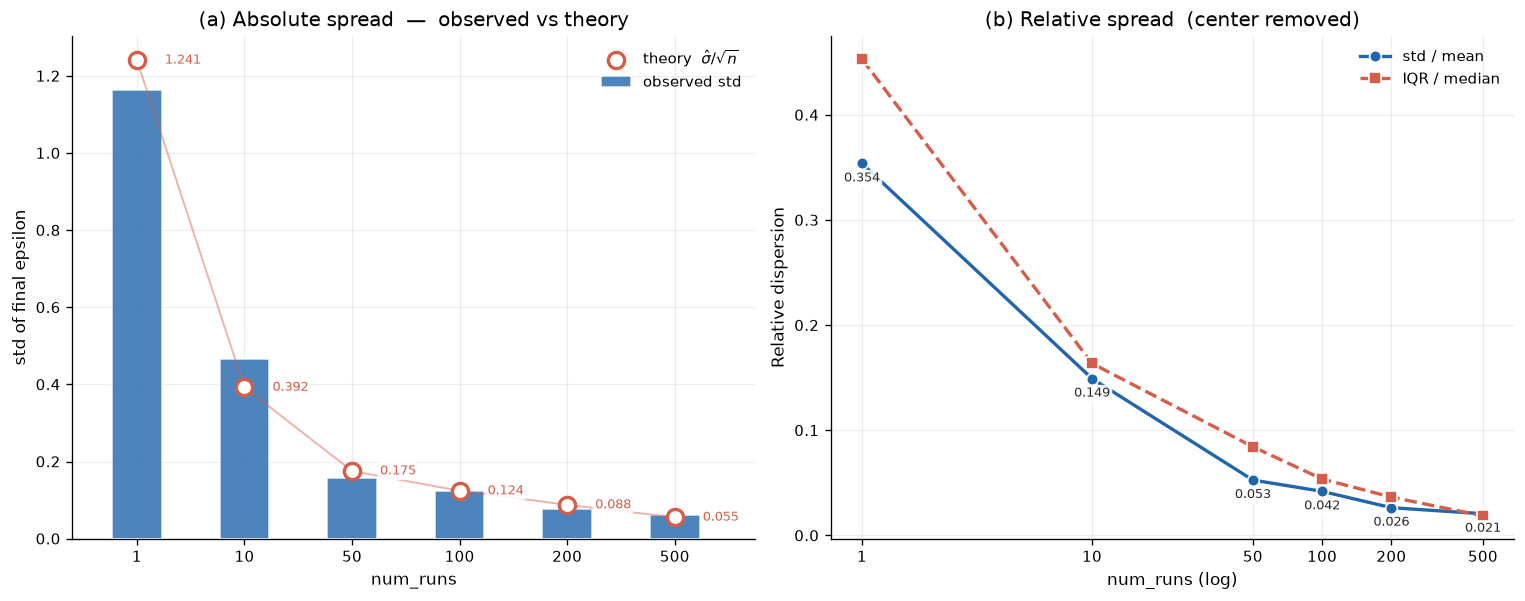

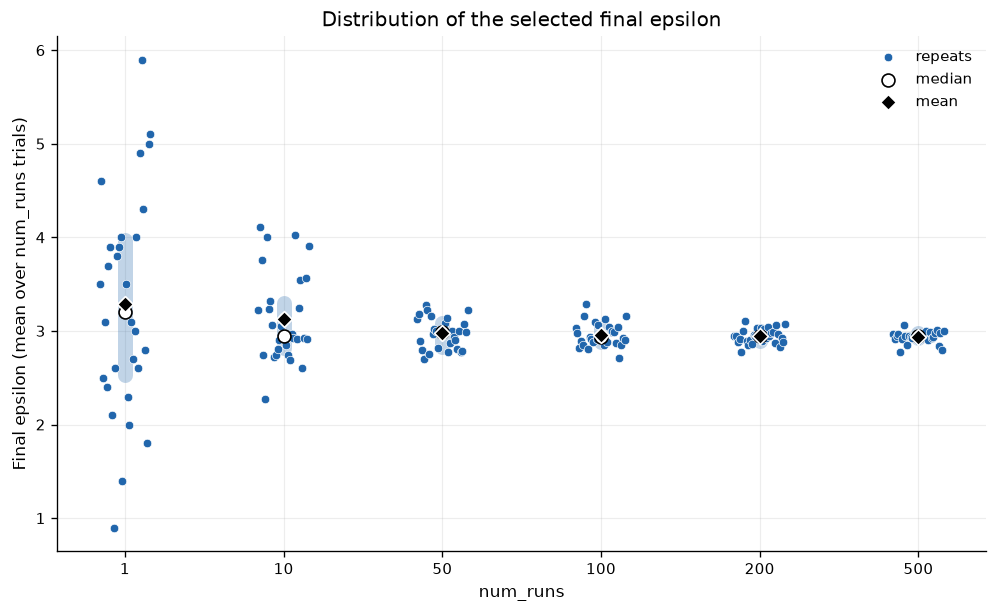

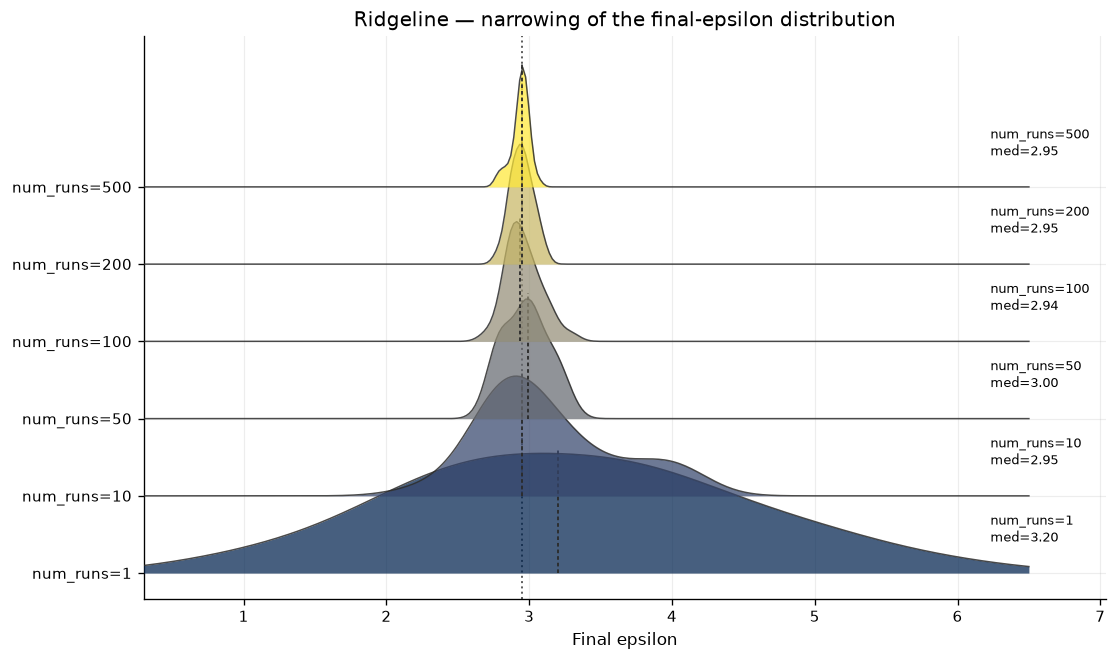

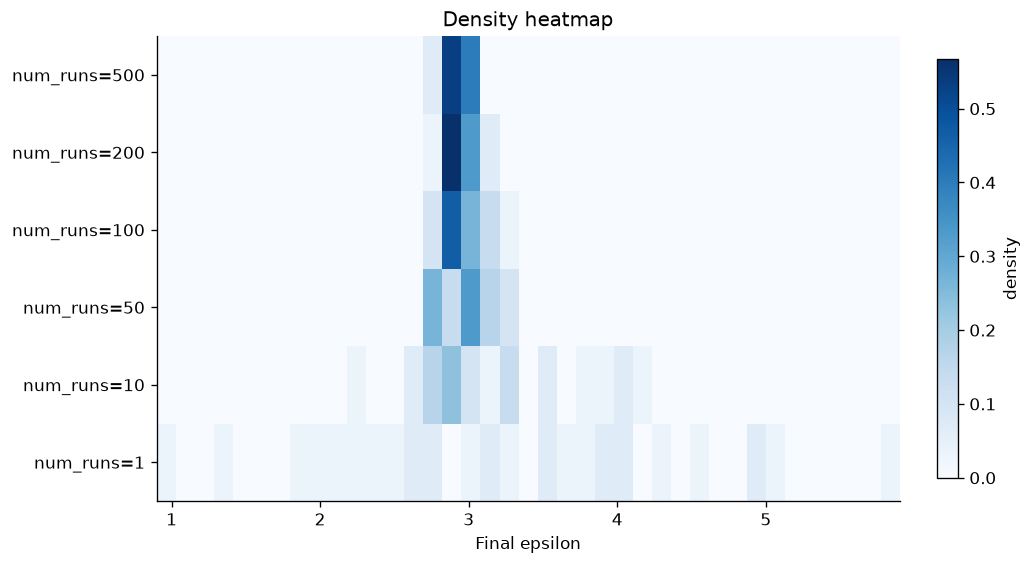

In [55]:
# (A) ax1 + ax2  — 나란히
plot_absolute_and_relative(sweep, summary);

# (B) 산점도
plot_trial_distribution(sweep);                      # 우측 std 축까지: show_std_axis=True

# (C) Ridgeline
plot_ridge(sweep);

# (D) Heatmap
plot_density_heatmap(sweep, cmap="Blues");

# 저장까지 하려면
# plot_absolute_and_relative(sweep, summary, save="fig_ab.png")
# plot_trial_distribution(sweep,               save="fig_scatter.png")
# plot_ridge(sweep,                            save="fig_ridge.png")
# plot_density_heatmap(sweep, save="fig_heat.png")

### 개별 시행 점검 (선택)

대표 시행(ε 기준 중앙 순위)의 궤적을 보고 싶으면 `_trial_trajectory()`로 재생성합니다.
시드는 `seed = seed0 + (rep-1)` 이므로 `trial_finals`에서 바로 꺼내 쓸 수 있습니다.


In [ ]:
# 예: 본 실험의 첫 실험(outer_rep=1)에서 대표 시행 궤적 뽑기
_tf, _ = run_inverse_live_vec(D, eps=0.1, threshold=0.05, streak_required=3,
                              initial_eps_total=3, step=1.03,
                              num_runs=50, max_rounds=50, maxq=MAXQ, seed0=2025)
_rep = representative_trial(_tf)
print(f"대표 시행: rep={int(_rep['rep'])} | k_stop={int(_rep['k_stop'])} | "
      f"ε={float(_rep['actual_eps_total']):.2f} | rounds={int(_rep['rounds_used'])}")

_traj = _trial_trajectory(D, eps=0.1, threshold=0.05, streak_required=3,
                          initial_eps_total=3, step=1.03, max_rounds=50, maxq=MAXQ,
                          seed=int(_rep["seed"]))

fig, axes = plt.subplots(1, 2, figsize=(13, 4.3), constrained_layout=True)
axes[0].plot(_traj["k"], _traj["cumulative_mean"], color="#2166AC", lw=1.8, label="Cumulative mean")
axes[0].fill_between(_traj["k"], _traj["ci_lo"], _traj["ci_hi"],
                     color="#2166AC", alpha=.13, label="95% CI")
axes[0].axhline(D["true_mean"], color="#1A9850", ls="--", label="True mean")
axes[0].set_title(f"Representative trial (rep={int(_rep['rep'])})")
axes[0].set_xlabel("Within-round query count k"); axes[0].set_ylabel("Query output")
axes[0].legend(frameon=False, fontsize=8)

axes[1].plot(_traj["k"], _traj["relative_width"], color="#2166AC", lw=1.8, label="Relative width")
axes[1].axhline(0.05, color="#D55E4A", ls="--", label="Threshold")
_tail = _traj.tail(int(_traj["streak_count"].iloc[-1]))
axes[1].scatter(_tail["k"], _tail["relative_width"], color="#D55E4A", s=35, zorder=3,
                label=f"Last {len(_tail)} checks")
axes[1].set_title(f"Final round check | actual eps={float(_rep['actual_eps_total']):.2f}")
axes[1].set_xlabel("Within-round query count k"); axes[1].set_ylabel("Relative CI width")
axes[1].legend(frameon=False, fontsize=8)
plt.show()


## 8. 해석 주의사항

**① 중심은 내려가지 않고 퍼짐만 줄어듭니다.**
`final_eps`는 내부 시행들의 **평균**이므로 `E[final_eps]`는 `num_runs`와 거의 무관합니다.
`num_runs`를 키우면 **분산이 줄어듭니다**(대략 `1/√num_runs`). 즉 얻는 것은 "ε이 작아진다"가 아니라
**"ε 추정이 재현 가능해진다"** 이며, 이것이 정확히 CAPRI Fig. 5의 논지입니다.
`ax0`에서 분포가 **세로로 좁아지되 중심은 그대로**인 모습이 나오면 정상입니다.

**② `num_runs = 1`을 반드시 포함하세요.**
이 값이 "반복이 전혀 없을 때의 분포"라는 **기준선**이고, 이후 값들이 그 기준선보다 얼마나 좁아지는지가
개편의 효과 그 자체입니다.

**③ ε 격자가 이산적입니다.**
`actual_eps_total = eps × k_stop` 이고 `eps = 0.1` 이므로 ε은 **0.1 간격 값만** 나옵니다.
따라서 `mode_share`(최빈 ε 점유율)는 연속 ε을 쓰는 CAPRI보다 **구조적으로 높게** 나옵니다.
점유율 하나에 의존하지 말고 **`std` / `iqr` / `p05–p95` 폭**을 주 지표로 쓰시길 권합니다.
(ε을 촘촘하게 보려면 `eps`를 더 작게 잡으세요.)

**④ 수렴률을 함께 보고하세요.**
`conv_rate`가 1.0이 아니면 `final_eps`는 **수렴한 시행만의 평균**입니다.
`max_rounds`·`initial_eps_total`·`step`을 조정해 `conv_rate = 1`로 만든 뒤 실험하시고,
불가피하게 1 미만이면 논문에 그 비율을 명시해야 합니다.

**⑤ 시뮬레이션 예산은 ε 합계에 포함되지 않습니다.**
CAPRI도 오프라인 서버측 시뮬레이션이므로 `num_runs`가 클라이언트의 프라이버시 손실을 늘리지 않습니다
(논문 6.1.2절). 참고문헌으로 명시하시면 됩니다.

**⑥ `_vec_run`은 라운드 루프를 벡터화했지만 시행 간 완전 독립입니다.**
시드가 시행·라운드별로 분리되어 있으므로(시행: `seed0+rep-1`, 라운드: `+round_no×1_000_003`),
결과는 순차 실행과 동일합니다. 4절 검증이 이를 확인합니다.
